<a href="https://colab.research.google.com/github/msanaullahchaudhary/kisaan-ai/blob/main/02_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!cp /content/drive/MyDrive/KisaanAI/data/raw.zip /content/
!unzip -q /content/raw.zip -d /content/
!ls /content/raw

plantdoc  plantvillage


In [3]:
import os
import pandas as pd
from PIL import Image

df = pd.read_csv('/content/drive/MyDrive/KisaanAI/data/splits.csv')

for path, cls, split in df.itertuples(index=False):
    folder = os.path.join('/content/splits', split, cls)
    os.makedirs(folder, exist_ok=True)
    new_name = path.replace('/', '_').rsplit('.', 1)[0] + '.jpg'
    with Image.open(os.path.join('/content/raw', path)) as im:
        im = im.convert('RGB')
        im.thumbnail((512, 512))
        im.save(os.path.join(folder, new_name), quality=92)

print(df['split'].value_counts())

split
lab_train      10547
lab_test        2261
lab_val         2258
field_train      550
field_val         98
field_test        68
Name: count, dtype: int64


In [4]:
import keras

CLASSES = ['Early_blight', 'Late_blight', 'Septoria_leaf_spot', 'Bacterial_spot',
           'Leaf_mold', 'Yellow_Leaf_Curl_Virus', 'Mosaic_virus', 'Healthy']
IMG_SIZE = 224
BATCH = 32

def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        f'/content/splits/{split}',
        class_names=CLASSES,
        label_mode='int',
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH,
        shuffle=shuffle,
        seed=42)

lab_train = load('lab_train', True)
lab_val = load('lab_val', False)

for images, labels in lab_train.take(1):
    print(images.shape, labels[:10].numpy())

Found 10547 files belonging to 8 classes.
Found 2258 files belonging to 8 classes.
(32, 224, 224, 3) [1 3 3 3 5 0 5 3 6 5]


In [5]:
import numpy as np

augment = keras.Sequential([
    keras.layers.RandomFlip('horizontal_and_vertical'),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom((-0.2, 0.1)),
    keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    keras.layers.RandomContrast(0.2),
])

train_ds = lab_train.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y)).prefetch(tf.data.AUTOTUNE)
val_ds = lab_val.prefetch(tf.data.AUTOTUNE)

counts = np.array([len(os.listdir(f'/content/splits/lab_train/{c}')) for c in CLASSES])
class_weight = {i: counts.sum() / (len(CLASSES) * counts[i]) for i in range(len(CLASSES))}
print(counts)
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

[ 700 1331 1240 1489  666 3750  261 1110]
{'Early_blight': np.float64(1.88), 'Late_blight': np.float64(0.99), 'Septoria_leaf_spot': np.float64(1.06), 'Bacterial_spot': np.float64(0.89), 'Leaf_mold': np.float64(1.98), 'Yellow_Leaf_Curl_Virus': np.float64(0.35), 'Mosaic_virus': np.float64(5.05), 'Healthy': np.float64(1.19)}


In [6]:
base = keras.applications.MobileNetV3Large(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet',
    include_preprocessing=True)
base.trainable = False

x = keras.layers.GlobalAveragePooling2D(name='gap')(base.output)
x = keras.layers.Dropout(0.3, name='dropout')(x)
logits = keras.layers.Dense(len(CLASSES), name='logits')(x)
outputs = keras.layers.Activation('softmax', name='predictions')(logits)
model = keras.Model(base.input, outputs)

print('Total layers:', len(model.layers))
print('Trainable numbers:', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Total layers: 191
Trainable numbers: 7688


In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

MODELS = '/content/drive/MyDrive/KisaanAI/models'
os.makedirs(MODELS, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage1.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weight,
    callbacks=callbacks)

Epoch 1/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 184s 498ms/step - accuracy: 0.7144 - loss: 0.9737 - val_accuracy: 0.8707 - val_loss: 0.4538
Epoch 2/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 143s 432ms/step - accuracy: 0.8634 - loss: 0.4871 - val_accuracy: 0.9066 - val_loss: 0.3157
Epoch 3/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 151s 456ms/step - accuracy: 0.8914 - loss: 0.3983 - val_accuracy: 0.9159 - val_loss: 0.2861
Epoch 4/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 146s 441ms/step - accuracy: 0.9012 - loss: 0.3451 - val_accuracy: 0.9300 - val_loss: 0.2443
Epoch 5/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 147s 444ms/step - accuracy: 0.9091 - loss: 0.3131 - val_accuracy: 0.9393 - val_loss: 0.2270
Epoch 6/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 145s 439ms/step - accuracy: 0.9110 - loss: 0.3043 - val_accuracy: 0.9376 - val_loss: 0.2103
Epoch 7/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 148s 449ms/step - accuracy: 0.9187 - loss: 0.2770 - val_accuracy: 0.9415 - val_loss: 0.2029
Epoch 8/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 146s 442ms/step - accuracy: 0.9165 - loss: 0

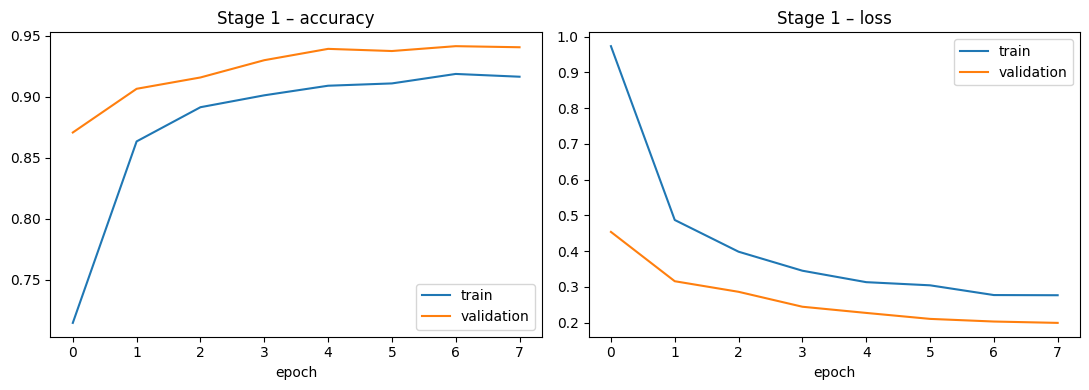

In [8]:
import matplotlib.pyplot as plt

h = history1.history
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h['accuracy'], label='train')
ax[0].plot(h['val_accuracy'], label='validation')
ax[0].set_title('Stage 1 – accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['loss'], label='train')
ax[1].plot(h['val_loss'], label='validation')
ax[1].set_title('Stage 1 – loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{MODELS}/stage1_curves.png', dpi=150)
plt.show()

In [ ]:
# Stage 2: let the top 40% of MobileNetV3 learn too
base.trainable = True
n = len(base.layers)
cut = int(n * 0.6)   # bottom 60% stays frozen

for i, layer in enumerate(base.layers):
    if i < cut or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print('Base layers that will learn:', sum(l.trainable for l in base.layers), 'of', n)

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks2 = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage2.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
]

history2 = model.fit(train_ds, validation_data=val_ds, epochs=12,
                     class_weight=class_weight, callbacks=callbacks2)